# Differential Functionalism: Jacobians Shape the Structure of Phenomenal Experience — computational companion

This notebook works through the examples in the paper, with some additional examples. It needs two files:

* `jacobians.py` — input and parameter Jacobians of any chosen neurons in a PyTorch model (`jacobian`, `capture`, `input_jacobian`, `parameter_jacobian`).
* `jacobian_measures.py` — transparency $\rho$, integrity $\iota$, integral rank $\rho\cdot\iota$, Fiedler vectors, coherency, the closed forms for convolution, and a spanning-tree measure that this notebook compares with integrity.

Requirements: `numpy`, `scipy`, `torch`, `scikit-learn`, `matplotlib`.
Running everything takes about two minutes on a laptop CPU. Figures are written to `notebook_figs/`.


| Paper | Notebook |
|---|---|
| §2.2 Quantifying Jacobian structure (Defs 1–3, Fig. 2) | §1 |
| §2.2 The constitution of boundaries (Def. 4) | §2 |
| §3.1 Shared inputs; independent decisions (Fig. 3; App. "Integrity: Interacting systems") | §3 |
| §3.2 Focus can select boundaries (Fig. 4, Table 1; App. "Optics of boundaries") | §4 |
| §3.3 The structure of duration (Figs 5–6) | §5 |
| §3.4 Spatial structure: convolution (App. "Closed form measures for convolutions") | §6 |
| §3.5 Jacobian facets can resemble inputs | §7 |
| §3.6 Vivid and obscure errors | §8 |
| §3.7 The structure of attention | §9 |
| §3.8 Shattered structure at initialisation (Fig. 9) | §10 |
| §3.9 Distinct and confused facets (Def. 5) | §11 |
| §3.10 Learning: higher-order structure | §12 |
| App. "Effective rank", "Integrity" | §13 |

In [1]:
# Imports, global settings, colour palette and small helpers used throughout.
import os
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from scipy.special import expit, logit

from jacobians import jacobian, input_jacobian, parameter_jacobian
from jacobian_measures import (
    transparency, integrity, integral_rank, drop_inert, fiedler,
    coherency, distinct_ideas, entropic_rank, spanning_tree_cohesion,
    effective_rank_trace, effective_rank_collision, effective_rank_cv,
    conv_integrity,
)

# Double precision everywhere in torch; compact numpy printing.
torch.set_default_dtype(torch.float64)
np.set_printoptions(precision=3, suppress=True)

# All figure files are written to this folder.
FIG_DIR = "notebook_figs"
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Colour palette shared by all figures.
BLUE, GOLD, BURG, GREY = "#3a6fb0", "#d29a1e", "#7b0828", "#9a9a9a"
GREEN, RED, ORANGE = "#2a9d3f", "#c8333b", "#f07f13"


def as_float(A):
    """Convert a 0-dim tensor (or a float) to a Python float."""
    return float(A)


def measures(A, name=""):
    """Print one line: transparency rho, integrity iota and integral rank rho*iota of A."""
    print(f"{name:38s} rho={as_float(transparency(A)):6.2f}  "
          f"iota={as_float(integrity(A)):.3f}  "
          f"rho*iota={as_float(integral_rank(A)):6.2f}")


def plot_heatmap(ax, A, title="", cmap="RdBu_r"):
    """Draw matrix A (tensor or array) on `ax`, without ticks.

    The diverging default colour map is centred at zero; other maps run from 0 to max|A|.
    """
    A = A.detach().numpy() if torch.is_tensor(A) else np.asarray(A)
    vmax = np.abs(A).max() or 1.0
    vmin = -vmax if cmap == "RdBu_r" else 0
    ax.imshow(A, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])

## 1. Quantifying Jacobian structure (§2.2)

**Transparency** $\rho(A)=(\sum\sigma_i^2)^2/\sum\sigma_i^4$ is the effective rank (Def. 1). **Integrity** $\iota(A)=1-\sigma_2(\mathcal A)$, with $\mathcal A=D_r^{-1/2}|A|D_c^{-1/2}$, is the normalised algebraic connectivity of the bipartite graph $G(A)$ (Def. 2). **Integral rank** is $\rho\cdot\iota$ (Def. 3).

The extremes quoted in §2.2: the identity maxes out transparency and has zero integrity; the all-ones matrix the reverse; a Hadamard matrix attains the bound $n$ on both together.

In [2]:
# §2.2 extremes: identity (max transparency, zero integrity), all-ones (the reverse),
# Hadamard (attains the joint bound n), plus some random matrices for comparison.
def hadamard(k):
    """Sylvester construction of the 2^k x 2^k Hadamard matrix (entries +-1)."""
    H = np.array([[1.0]])
    for _ in range(k):
        H = np.block([[H, H], [H, -H]])
    return H


n = 8                              # matrix size
H = hadamard(3)                    # 8 x 8; reused in §11
rng = np.random.default_rng(0)     # shared by this cell and the next

measures(np.eye(n), "identity")
measures(np.ones((n, n)), "all-ones")
measures(H, "Hadamard (bound = n = 8)")
measures(np.kron(np.eye(2), rng.random((4, 4)) + .2), "block diagonal")
measures(rng.standard_normal((n, n)), "Gaussian")
measures(np.outer(rng.lognormal(size=n), rng.lognormal(size=n)),
         "|A| rank one (uneven entries)")

# Average integral rank of random Gaussian matrices.
gaussian_ranks = [integral_rank(rng.standard_normal((n, n))) for _ in range(1000)]
print("mean integral rank of 1000 Gaussian 8x8:", np.mean(gaussian_ranks).round(2))

identity                               rho=  8.00  iota=0.000  rho*iota=  0.00
all-ones                               rho=  1.00  iota=1.000  rho*iota=  1.00
Hadamard (bound = n = 8)               rho=  8.00  iota=1.000  rho*iota=  8.00
block diagonal                         rho=  2.42  iota=0.000  rho*iota=  0.00
Gaussian                               rho=  4.07  iota=0.625  rho*iota=  2.54
|A| rank one (uneven entries)          rho=  1.00  iota=1.000  rho*iota=  1.00
mean integral rank of 1000 Gaussian 8x8: 2.32


**Inert nodes.** A single all-zero column disconnects $G(A)$. Def. 2 removes inert rows and columns first (`drop=True`, the default).

In [3]:
# Two all-zero (dead) columns disconnect G(A); Def. 2 drops such inert nodes first.
A = rng.standard_normal((4, 6))
A[:, [1, 4]] = 0                   # two dead units
print("raw graph (drop=False):", integrity(A, drop=False),
      "  inert nodes dropped:", round(integrity(A), 3))

raw graph (drop=False): 0.0   inert nodes dropped: 0.569


### Fig. 2: effective rank and the weakest seam
The matrices below are the ones drawn in the bottom row of Fig. 2, and the singular values are the bar heights in the top row. The labels printed in the figure are recomputed here.

In [4]:
# Fig. 2, bottom row: a matrix with a weak seam vs a dense one. Prints integrity and the
# sign patterns of the Fiedler vectors over rows (y) and columns (x).
seam = np.array([[0.80, 0.35, 0, ],
                 [0.60, 0.90, 0.05],
                 [0, 0.05, 0.70],
                 [0, 0, 0.50]])
dense = np.array([[0.85, 0.40, 0.20],
                  [0.55, 0.75, 0.15],
                  [0.30, 0.65, 0.45],
                  [0.70, 0.25, 0.80]])
for title, A in (("weak seam", seam), ("no weak seam", dense)):
    fiedler_y, fiedler_x = fiedler(A)
    print(f"{title:13s}: integrity {as_float(integrity(A)):.2f}; "
          f"Fiedler signs  y={np.sign(fiedler_y).astype(int)}  "
          f"x={np.sign(fiedler_x).astype(int)}")

# Removing the two 0.05 entries disconnects the seam matrix.
seam_cut = seam.copy()
seam_cut[1, 2] = seam_cut[2, 1] = 0
print("without the two 0.05 entries: iota =", integrity(seam_cut))

# Fig. 2, top row: effective rank of the two plotted singular-value profiles.
for label, sing_vals in (("low", [1, .267, .069]), ("high", [1, .795, .739])):
    print(f"effective rank, {label}: {as_float(transparency(np.diag(sing_vals))):.1f}")

weak seam    : integrity 0.06; Fiedler signs  y=[ 1  1 -1 -1]  x=[ 1  1 -1]
no weak seam : integrity 0.65; Fiedler signs  y=[ 1  1  1 -1]  x=[ 1  1 -1]
without the two 0.05 entries: iota = 0.0
effective rank, low: 1.2
effective rank, high: 2.8


## 2. The constitution of boundaries (Def. 4)

A **unit** is a candidate (outputs, parameters, and an input cut through which every path into the outputs passes) that locally maximises integral rank: adding or removing outputs and parameters is scored on $\iota_\rho(J_{y\leftarrow\mathcal W})$; changing temporal coordinates, or replacing input nodes with upstream ones or output nodes with downstream ones, on $\iota_\rho(J_{y\leftarrow x})$. The examples move only the input side. The paper uses three instances: *merge* (§3), *extend* (§4) and *duration* (§5).

The paper adds: "A candidate with a single output, or a single input, has a rank-one Jacobian and integral rank exactly 1 … It is a unit whenever its neighbours score below 1." Whether it is a local maximum does depend on its neighbours: a two-output neighbour whose Jacobian is a $2\times2$ Hadamard block scores 2:

In [5]:
# A single output has integral rank 1; a two-output neighbour whose Jacobian is a 2x2
# Hadamard block scores 2, so the single output is not a local maximum (Def. 4).
J_single = np.array([[1.0, 1.0]])
J_hadamard2 = np.array([[1.0, 1.0], [1.0, -1.0]])
print("single output: integral rank", integral_rank(J_single),
      "| add a second output:", integral_rank(J_hadamard2))
print("-> the single output is not a local maximum here, so it is not a unit under Def. 4.")

single output: integral rank 1.0 | add a second output: 2.0
-> the single output is not a local maximum here, so it is not a unit under Def. 4.


A worked example: one input $x=1$, parameters $w_1,w_2,w_3$, outputs $y_1=(w_1+w_2)x$, $y_2=(w_1-w_2)x$, $y_3=w_3x$, scored on the parameter Jacobian.

In [6]:
# Worked example of Def. 4: score candidates (outputs, parameters) by the integral rank of
# the matching block of the parameter Jacobian J_{y <- w}.
w = torch.ones(3, requires_grad=True)
x1 = torch.tensor(1.0)
outputs = torch.stack([(w[0] + w[1]) * x1, (w[0] - w[1]) * x1, w[2] * x1])
Jw = jacobian(outputs, w)          # rows y1..y3, columns w1..w3


def candidate_score(outs, pars):
    """Integral rank of the block of Jw with output rows `outs` and parameter columns `pars`."""
    return as_float(integral_rank(Jw[outs][:, pars]))


# (label, output indices, parameter indices)
candidates = (
    ("{y1}", [0], [0, 1]),
    ("{y1, y2}", [0, 1], [0, 1]),
    ("{y1, y2} without w2", [0, 1], [0]),
    ("{y1, y2} plus w3", [0, 1], [0, 1, 2]),
    ("{y1, y2} plus y3", [0, 1, 2], [0, 1, 2]),
    ("{y3}", [2], [2]),
    ("{y3} plus y1", [0, 2], [0, 1, 2]),
)
for label, outs, pars in candidates:
    print(f"{label:22s} integral rank {candidate_score(outs, pars):.0f}")

{y1}                   integral rank 1
{y1, y2}               integral rank 2
{y1, y2} without w2    integral rank 1
{y1, y2} plus w3       integral rank 2
{y1, y2} plus y3       integral rank 0
{y3}                   integral rank 1
{y3} plus y1           integral rank 0


In the examples that follow (focus, EMAs) a single output does score above its neighbours, so the baseline is a unit there. An *extended unit* is a unit that beats this baseline; the *duration* instance asks for one (§5).

## 3. Shared inputs; independent decisions (§3.1, Fig. 3)

Two nets see the same input. The input Jacobian of their stacked outputs is connected, $\iota>0$: our experiences overlap. The parameter Jacobian is block diagonal, $\iota=0$: our decisions are independent.

input Jacobian  J_{y1,y2 <- x}         rho=  2.55  iota=0.493  rho*iota=  1.26
parameter Jacobian J_{y1,y2 <- V,W}    rho=  3.84  iota=0.000  rho*iota=  0.00


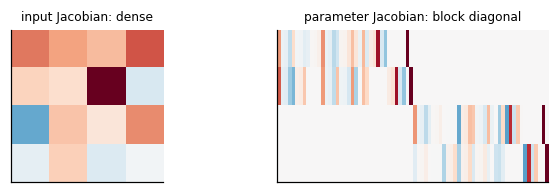

In [7]:
# Fig. 3: two independent nets ("you" and "me") see the same input ("tree"). The input
# Jacobian of the stacked outputs is dense (iota > 0: overlapping experience); the
# parameter Jacobian is block diagonal (iota = 0: independent decisions).
torch.manual_seed(6)
you = nn.Sequential(nn.Linear(4, 5), nn.Tanh(), nn.Linear(5, 2))
me = nn.Sequential(nn.Linear(4, 5), nn.Tanh(), nn.Linear(5, 2))
tree = torch.randn(4, requires_grad=True)
y_you, y_me = you(tree), me(tree)
J_in = jacobian([y_you, y_me], tree)
J_par = jacobian([y_you, y_me], list(you.parameters()) + list(me.parameters()))
measures(J_in, "input Jacobian  J_{y1,y2 <- x}")
measures(J_par, "parameter Jacobian J_{y1,y2 <- V,W}")

fig, axs = plt.subplots(1, 2, figsize=(7, 1.8))
plot_heatmap(axs[0], J_in, "input Jacobian: dense")
plot_heatmap(axs[1], J_par, "parameter Jacobian: block diagonal")
axs[1].set_aspect("auto")
plt.show()

### Interacting systems: when does talking merge two units? (§3.1; App. "Integrity: Interacting systems")
Two 64–32–32–10 relu MLPs are trained separately to 100% training accuracy on the scikit-learn digits. Each second hidden layer then receives $\epsilon$ times a fixed random projection of the other net's first hidden layer (in the one-way case only one net receives it). By the *merge* instance of Def. 4, the pair is one unit iff $\iota_\rho(J_{y_a,y_b\leftarrow\mathcal W_a,\mathcal W_b})\ge\max\{\iota_\rho(J_{y_a\leftarrow\mathcal W_a}),\iota_\rho(J_{y_b\leftarrow\mathcal W_b})\}$, on the parameter Jacobian of the 20 joint logits at one input.

The spanning-tree alternative (`spanning_tree_cohesion`) is zero whenever a dead relu leaves an all-zero column, so it is computed on the live columns (`drop_inert`), as integrity is.

In [8]:
# §3.1, App. "Integrity: Interacting systems": two digit classifiers are coupled through a
# random projection of each other's first hidden layer (strength eps). The *merge* instance
# of Def. 4 compares the merged pair's integral rank with the better of the two apart.
from sklearn.datasets import load_digits

COUPLING_EPS = [0, 0.01, 0.1, 0.5, 1, 1.5, 2, 3]   # coupling strengths eps

# Digits: 1797 images of 8x8 pixels scaled to [0, 1], labels 0..9.
Xd, yd = load_digits(return_X_y=True)
Xd, yd = torch.tensor(Xd / 16.0), torch.tensor(yd)


def train_digits_mlp(seed):
    """Train a 64-32-32-10 relu MLP (Adam, lr 1e-2, full batch) on all digits until it
    classifies every training image correctly. Returns its three Linear layers."""
    torch.manual_seed(seed)
    net = nn.ModuleList([nn.Linear(64, 32), nn.Linear(32, 32), nn.Linear(32, 10)])

    def forward(x):
        return net[2](torch.relu(net[1](torch.relu(net[0](x)))))

    opt = torch.optim.Adam(net.parameters(), 1e-2)
    while (forward(Xd).argmax(1) != yd).any():
        opt.zero_grad()
        nn.functional.cross_entropy(forward(Xd), yd).backward()
        opt.step()
    return net


nets = [train_digits_mlp(0), train_digits_mlp(1)]
proj_gen = torch.Generator().manual_seed(0)
proj = [torch.randn(32, 32, generator=proj_gen) / np.sqrt(32) for _ in range(2)]


def talk(x, eps, two_way):
    """Coupled forward pass on input x. Net b's second hidden layer receives
    eps * proj[1] @ (net a's first hidden layer); net a receives the converse only if
    `two_way`. Returns the logits (y_a, y_b)."""
    a, b = nets
    h1a, h1b = torch.relu(a[0](x)), torch.relu(b[0](x))
    h2a = torch.relu(a[1](h1a) + (eps * proj[0] @ h1b if two_way else 0))
    h2b = torch.relu(b[1](h1b) + eps * proj[1] @ h1a)
    return a[2](h2a), b[2](h2b)


def cohesive_rank(J):
    """Spanning-tree analogue of integral rank: transparency times the spanning-tree
    cohesion of the live (non-inert) part of J."""
    return as_float(transparency(J)) * as_float(spanning_tree_cohesion(drop_inert(J)))


params_a, params_b = list(nets[0].parameters()), list(nets[1].parameters())
x0 = Xd[0]                         # the input at which the Jacobians are taken
talk_results = {}                  # (two_way, eps) -> (apart, merged) integral ranks
for two_way in (True, False):
    print("two-way" if two_way else "one-way")
    for eps in COUPLING_EPS:
        ya, yb = talk(x0, eps, two_way)
        J_ya = jacobian(ya, params_a)
        J_yb = jacobian(yb, params_b)
        J_merged = jacobian([ya, yb], params_a + params_b)
        apart = max(as_float(integral_rank(J_ya)), as_float(integral_rank(J_yb)))
        merged = as_float(integral_rank(J_merged))
        talk_results[two_way, eps] = (apart, merged)
        verdict = 'ONE unit ' if merged >= apart else 'two units'
        tree_apart = max(cohesive_rank(J_ya), cohesive_rank(J_yb))
        tree_merged = cohesive_rank(J_merged)
        print(f"  eps={eps:<5g} integral rank: apart {apart:.2f}  merged {merged:.2f}  "
              f"-> {verdict}  | spanning-tree version: "
              f"apart {tree_apart:.1f}  merged {tree_merged:.1f}")

two-way
  eps=0     integral rank: apart 4.74  merged 0.00  -> two units  | spanning-tree version: apart 6.8  merged 0.0
  eps=0.01  integral rank: apart 4.74  merged 0.04  -> two units  | spanning-tree version: apart 6.8  merged 13.0
  eps=0.1   integral rank: apart 4.74  merged 0.43  -> two units  | spanning-tree version: apart 6.8  merged 13.1
  eps=0.5   integral rank: apart 4.73  merged 1.90  -> two units  | spanning-tree version: apart 6.8  merged 13.2
  eps=1     integral rank: apart 4.99  merged 3.36  -> two units  | spanning-tree version: apart 6.9  merged 13.5
  eps=1.5   integral rank: apart 5.02  merged 4.43  -> two units  | spanning-tree version: apart 6.9  merged 13.6
  eps=2     integral rank: apart 4.90  merged 5.32  -> ONE unit   | spanning-tree version: apart 7.2  merged 13.9
  eps=3     integral rank: apart 4.74  merged 6.27  -> ONE unit   | spanning-tree version: apart 7.2  merged 14.2
one-way
  eps=0     integral rank: apart 4.74  merged 0.00  -> two units  | spann

In [9]:
# One-way coupling: merged < apart for every nonzero eps, so the pair never merges.
print("one-way coupling keeps two units for every eps <= 3:",
      all(talk_results[False, eps][1] < talk_results[False, eps][0]
          for eps in COUPLING_EPS[1:]))

one-way coupling keeps two units for every eps <= 3: True


**Over seeds and inputs.** The same test for ten pairs of nets (training seeds $2k, 2k+1$ and projection seed $k$) at ten inputs each (input 0 and nine random digits): the count of (pair, input) cases in which the pair is one unit, and the ratio of merged to apart integral rank.

In [10]:
# Robustness of the merge test: N_PAIRS pairs of nets (training seeds 2k, 2k+1; projection
# seed k), each at N_INPUTS inputs (input 0, then random digits from permutation seed 100+k).
MERGE_EPS = [0.5, 1, 1.5, 2, 3]    # coupling strengths tested
N_PAIRS = 10                       # pairs of independently trained nets
N_INPUTS = 10                      # test inputs per pair

# (two_way, eps) -> list of (is one unit, merged / apart) over all (pair, input) cases
merge_results = {(two_way, eps): [] for two_way in (True, False) for eps in MERGE_EPS}
for k in range(N_PAIRS):
    # The k-th pair of nets and its coupling projections.
    pair_nets = [train_digits_mlp(2 * k), train_digits_mlp(2 * k + 1)]
    pair_gen = torch.Generator().manual_seed(k)
    pair_proj = [torch.randn(32, 32, generator=pair_gen) / np.sqrt(32) for _ in range(2)]
    pair_params_a = list(pair_nets[0].parameters())
    pair_params_b = list(pair_nets[1].parameters())

    # Test inputs: input 0, then the first N_INPUTS - 1 entries of a seeded permutation.
    perm = torch.randperm(len(Xd), generator=torch.Generator().manual_seed(100 + k))
    input_indices = [0] + list(perm[:N_INPUTS - 1].numpy())

    for i in input_indices:
        x = Xd[int(i)]
        h1a = torch.relu(pair_nets[0][0](x))
        h1b = torch.relu(pair_nets[1][0](x))
        for two_way in (True, False):
            for eps in MERGE_EPS:
                # The coupled forward pass of `talk`, for this pair.
                ya = pair_nets[0][2](torch.relu(
                    pair_nets[0][1](h1a) + (eps * pair_proj[0] @ h1b if two_way else 0)))
                yb = pair_nets[1][2](torch.relu(
                    pair_nets[1][1](h1b) + eps * pair_proj[1] @ h1a))
                apart = max(as_float(integral_rank(jacobian(ya, pair_params_a))),
                            as_float(integral_rank(jacobian(yb, pair_params_b))))
                merged = as_float(integral_rank(
                    jacobian([ya, yb], pair_params_a + pair_params_b)))
                merge_results[two_way, eps].append((merged >= apart, merged / apart))

# Per coupling: number of one-unit cases, and mean +- sd of merged / apart.
for two_way in (True, False):
    print("two-way" if two_way else "one-way")
    for eps in MERGE_EPS:
        cases = merge_results[two_way, eps]
        is_one_unit = np.array([case[0] for case in cases])
        rank_ratio = np.array([case[1] for case in cases])
        print(f"  eps={eps:<4g} one unit in {is_one_unit.sum():3d}/{len(is_one_unit)}   "
              f"merged/apart {rank_ratio.mean():.2f} ± {rank_ratio.std():.2f}")

two-way
  eps=0.5  one unit in   0/100   merged/apart 0.41 ± 0.02
  eps=1    one unit in   0/100   merged/apart 0.71 ± 0.03
  eps=1.5  one unit in   5/100   merged/apart 0.93 ± 0.04
  eps=2    one unit in  96/100   merged/apart 1.09 ± 0.05
  eps=3    one unit in 100/100   merged/apart 1.29 ± 0.06
one-way
  eps=0.5  one unit in   0/100   merged/apart 0.20 ± 0.02
  eps=1    one unit in   0/100   merged/apart 0.35 ± 0.03
  eps=1.5  one unit in   0/100   merged/apart 0.46 ± 0.04
  eps=2    one unit in   0/100   merged/apart 0.55 ± 0.04
  eps=3    one unit in   0/100   merged/apart 0.67 ± 0.05


With two-way coupling the nets stay apart at $\epsilon=1$ and merge at $\epsilon=2$; one-way coupling never merges them. The spanning-tree measure, by contrast, merges them as soon as any coupling exists ($\epsilon=0.01$).

## 4. Focus can select boundaries (§3.2, Fig. 4, App. "Optics of boundaries")

**Model.** A signpost at 2 m and a tree at 50 m, $n=16$ points each, one photoreceptor per point. The segment from scene to retina is $S=\mathrm{diag}(S_{\rm sign},S_{\rm tree})$; the stage after the retina is a dense Gaussian $D$ ($64\times32$), 100 draws. Defocus blurs each point over a Gaussian of width $c\,a\,|\Delta P|$ photoreceptors (pupil $a=4$ mm, $c=2$). By the *extend* instance of Def. 4, the cut moves upstream through a segment iff $\iota_\rho(DS)\ge\iota_\rho(D)$, so everything is reported as the ratio $\iota_\rho(DS)/\iota_\rho(D)$.

In [11]:
# §4 optics model: a signpost and a tree, a segment S from scene to retina, and a dense
# post-retina stage D. Constants:
N_PTS, N_DRAWS = 16, 100           # points (= photoreceptors) per object; draws of D
PUPIL, C_BLUR = 4.0, 2.0           # pupil diameter a (mm); blur constant c
V, SIGMA = 100.0, 0.05             # fog visibility V (m); noise level sigma
BETA = 3.912 / V                   # Koschmieder extinction coefficient
D_SIGN, D_TREE = 2.0, 50.0         # distances (m) of the signpost and the tree

# The post-retina stage: N_DRAWS dense Gaussian 64 x 32 matrices D.
rng = np.random.default_rng(0)
Ds = [rng.standard_normal((64, 2 * N_PTS)) for _ in range(N_DRAWS)]

# Columns of D seen by each object, and 16 x 16 identity / zero blocks.
SIGN, TREE, BOTH = slice(0, N_PTS), slice(N_PTS, 2 * N_PTS), slice(0, 2 * N_PTS)
I16, Z16 = np.eye(N_PTS), np.zeros((N_PTS, N_PTS))


def blur(width):
    """Defocus: each point's light spread over a Gaussian of `width` photoreceptors.

    Returns the N_PTS x N_PTS blur matrix (columns sum to 1).
    """
    if width < 1e-9:
        return np.eye(N_PTS)
    i = np.arange(N_PTS)
    K = np.exp(-0.5 * ((i[:, None] - i[None, :]) / width) ** 2)
    return K / K.sum(0, keepdims=True)


def blur_width(focus, dist, c=C_BLUR):
    """Blur width (photoreceptors) of an object at `dist` m when focused at `focus` m."""
    return c * PUPIL * abs(1 / focus - 1 / dist)


def veil(gam):
    """Fog segment: a fraction `gam` of the light stays put, the rest spreads evenly
    over the object's points."""
    return gam * I16 + (1 - gam) * np.ones((N_PTS, N_PTS)) / N_PTS


def pair(A, B):
    """Two-object segment S = diag(A, B) (signpost block A, tree block B)."""
    return np.block([[A, Z16], [Z16, B]])


def ratio(S, cols=BOTH, draws=Ds):
    """Integral rank of downstream x segment, relative to the boundary at the retina, per draw.

    Uses columns `cols` of each D; returns the array of iota_rho(D S) / iota_rho(D).
    """
    return np.array([as_float(integral_rank(D[:, cols] @ S)) / as_float(integral_rank(D[:, cols]))
                     for D in draws])

### Focus
"With a single object as input" means the system's inputs are that object's 16 photoreceptors only (the matching 16 columns of $D$).

In [12]:
# Single object: in focus the segment is the identity (ratio 1); the out-of-focus tree's
# blur lowers integral rank.
w_tree = blur_width(D_SIGN, D_TREE)          # tree blur, focus on the signpost
r_tree = ratio(blur(w_tree), TREE)
r_in_focus = ratio(blur(0), SIGN)
print(f"focused on the signpost, the tree is blurred over {w_tree:.2f} photoreceptors; "
      f"focused at infinity, {C_BLUR * PUPIL / D_TREE:.2f}")
print(f"in focus, the segment leaves integral rank unchanged (ratio {r_in_focus.mean():.3f}); "
      f"out of focus, the tree keeps {r_tree.mean():.2f} of it, "
      f"lowered in {np.mean(r_tree < 1):.0%} of draws")

focused on the signpost, the tree is blurred over 3.84 photoreceptors; focused at infinity, 0.16
in focus, the segment leaves integral rank unchanged (ratio 1.000); out of focus, the tree keeps 0.13 of it, lowered in 100% of draws


**The two-object scene.** With both objects in view, the outputs depend on all 32 photoreceptors, so the candidates compared by *extend* are $D$ (both at the retina), $D\,\mathrm{diag}(I,S_{\rm tree})$, $D\,\mathrm{diag}(S_{\rm sign},I)$ and $D\,S$. With the signpost in focus its segment is the identity, so $D\,\mathrm{diag}(I,S_{\rm tree})$ *is* the both-objects composite at that focus. Extending through the in-focus signpost is free; extending through the out-of-focus tree is not; refocusing swaps them.

In [13]:
# Two-object scene: extending through the in-focus object is free, through the
# out-of-focus one is not; refocusing swaps them.
B_tree = blur(blur_width(D_SIGN, D_TREE))    # tree segment, focus on the signpost
B_sign = blur(blur_width(D_TREE, D_SIGN))    # signpost segment, focus on the tree
r_joint = ratio(pair(I16, B_tree))
r_identity = ratio(pair(I16, I16)).mean()    # both segments in focus
r_sign_blurred = ratio(pair(B_sign, I16)).mean()
print(f"two-object scene, focus on signpost: extend through the signpost {r_identity:.3f}; "
      f"through the tree {r_joint.mean():.3f} "
      f"(range {r_joint.min():.2f}-{r_joint.max():.2f}, "
      f"below 1 in {np.mean(r_joint < 1):.0%})")
print(f"two-object scene, focus on tree:     extend through the tree {r_identity:.3f}; "
      f"through the signpost {r_sign_blurred:.3f}")

two-object scene, focus on signpost: extend through the signpost 1.000; through the tree 0.616 (range 0.57-0.65, below 1 in 100%)
two-object scene, focus on tree:     extend through the tree 1.000; through the signpost 0.617


Def. 4's neighbours change one node at a time, while *extend* moves a whole 16-node segment. Replacing a single photoreceptor by the points that feed it is not a valid cut when the segment mixes (those points also reach the outputs through the neighbouring photoreceptors), so for a blurred segment the segment-level move is the smallest valid one.

### Depth of field, robustness, and the curve over focus distance (Fig. 4a)

In [14]:
# Fig. 4a: integral-rank ratio against focus distance, each object alone and both together.
focus_dists = np.geomspace(1.5, 100, 160)    # focus distances F (m)
foc_sign = np.array([ratio(blur(blur_width(F, D_SIGN)), SIGN).mean() for F in focus_dists])
foc_tree = np.array([ratio(blur(blur_width(F, D_TREE)), TREE).mean() for F in focus_dists])
foc_both = np.array([
    ratio(pair(blur(blur_width(F, D_SIGN)), blur(blur_width(F, D_TREE)))).mean()
    for F in focus_dists
])
print(f"both objects: best focus {focus_dists[foc_both.argmax()]:.1f} m "
      f"(ratio {foc_both.max():.3f}); "
      f"at the signpost (2 m) {ratio(pair(I16, B_tree)).mean():.3f}")

# Depth of field. The tree "transmits" while its single-object ratio stays above 0.999.
# That happens below a fixed blur width w*, found by bisection (40 halvings of [0, 1]);
# the focus distance where the blur reaches w* is the depth of field.
lo, hi = 0.0, 1.0
for _ in range(40):
    w_mid = (lo + hi) / 2
    if ratio(blur(w_mid), TREE).mean() > 0.999:
        lo = w_mid
    else:
        hi = w_mid
w_star = lo

# Robustness to the blur constant c.
dof = {}                           # c -> depth of field (m)
for c in (1.0, 2.0, 4.0):
    best_both = max(
        ratio(pair(blur(blur_width(F, D_SIGN, c)), blur(blur_width(F, D_TREE, c)))).mean()
        for F in focus_dists
    )
    dof[c] = 1 / (1 / D_TREE + w_star / (c * PUPIL))
    tree_keeps = ratio(blur(blur_width(D_SIGN, D_TREE, c)), TREE).mean()
    print(f"c={c:g}: out-of-focus tree keeps {tree_keeps:.2f}; "
          f"both objects, best {best_both:.2f}; "
          f"tree transmits for focus beyond {dof[c]:.0f} m")

both objects: best focus 16.2 m (ratio 0.623); at the signpost (2 m) 0.616
c=1: out-of-focus tree keeps 0.24; both objects, best 0.70; tree transmits for focus beyond 9 m
c=2: out-of-focus tree keeps 0.13; both objects, best 0.62; tree transmits for focus beyond 16 m
c=4: out-of-focus tree keeps 0.09; both objects, best 0.57; tree transmits for focus beyond 24 m


### Fog (Fig. 4b, Table 1)
A fraction $T=e^{-\beta d}$ of the light arrives unscattered, $\beta=3.912/V$; the rest spreads over the object, $S_{\rm tree}=T I+(1-T)\mathbf 1\mathbf 1^\intercal/n$. The Wiener gain $g=T/(T^2+\sigma^2)$ leaves contrast factor $\gamma_u=T^2/(T^2+\sigma^2)$, and contrast collapses past $d^*=V\ln(1/\sigma)/3.912$. The signpost stays in focus, so this is already the two-object scene.

In [15]:
# Fog (Fig. 4b, Table 1): unscattered fraction T, Wiener gain and residual contrast gamma_u
# at several tree distances, with the integral-rank ratio before and after the gain.
d_star = V * np.log(1 / SIGMA) / 3.912     # distance at which contrast collapses
print(f"d* = {d_star:.0f} m, {d_star / V:.2f} of the visibility")
print("   d      T    gain  gamma_u | integral-rank ratio: at receptors  after gain")
for d in (10, 50, 77, 100, 150):
    T = np.exp(-BETA * d)                        # unscattered fraction
    gamma_u = T ** 2 / (T ** 2 + SIGMA ** 2)     # contrast factor left by the gain
    r_receptors = ratio(pair(I16, veil(T))).mean()
    r_after_gain = ratio(pair(I16, veil(gamma_u))).mean()
    print(f"{d:4d}  {T:.3f}  {T / (T ** 2 + SIGMA ** 2):5.1f}   {gamma_u:.3f}  |  "
          f"{r_receptors:.3f}            {r_after_gain:.3f}")


def gamma_after_gain(d):
    """gamma_u at tree distance d, as exp(-2 beta d) / (exp(-2 beta d) + sigma^2)."""
    return np.exp(-2 * BETA * d) / (np.exp(-2 * BETA * d) + SIGMA ** 2)


# Fig. 4b curves: ratio against tree distance, at the receptors and after the gain.
tree_dists = np.linspace(0, 200, 101)
fog_rec = np.array([ratio(pair(I16, veil(np.exp(-BETA * d)))).mean() for d in tree_dists])
fog_gain = np.array([ratio(pair(I16, veil(gamma_after_gain(d)))).mean() for d in tree_dists])
print(f"after gain, the ratio stays at or above 0.99 out to "
      f"{tree_dists[fog_gain >= 0.99].max():.0f} m")

d* = 77 m, 0.77 of the visibility
   d      T    gain  gamma_u | integral-rank ratio: at receptors  after gain
  10  0.676    1.5   0.995  |  0.914            1.000
  50  0.141    6.3   0.889  |  0.610            0.990
  77  0.049   10.0   0.492  |  0.563            0.803
 100  0.020    6.9   0.138  |  0.554            0.608
 150  0.003    1.1   0.003  |  0.552            0.552
after gain, the ratio stays at or above 0.99 out to 48 m


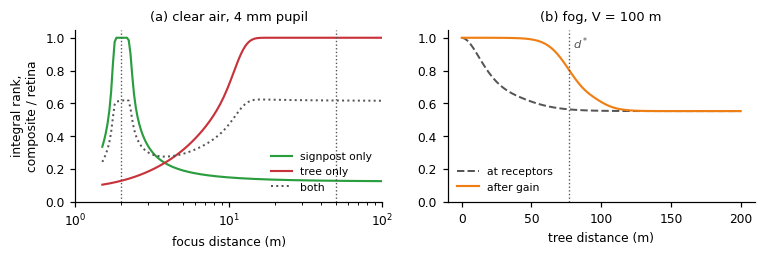

In [16]:
# Fig. 4 (boundaries_composite.pdf): (a) focus sweep in clear air; (b) fog.
fig, axs = plt.subplots(1, 2, figsize=(7.0, 2.4))

# Panel (a): ratio against focus distance; dotted lines at the two objects.
ax = axs[0]
ax.plot(focus_dists, foc_sign, color=GREEN, lw=1.4, label="signpost only")
ax.plot(focus_dists, foc_tree, color=RED, lw=1.4, label="tree only")
ax.plot(focus_dists, foc_both, color="#555555", lw=1.3, ls=":", label="both")
for d in (D_SIGN, D_TREE):
    ax.axvline(d, color="#555555", lw=0.9, ls=":")
ax.set(xscale="log", xlim=(1, 100), ylim=(0, 1.05), xlabel="focus distance (m)",
       ylabel="integral rank,\ncomposite / retina")
ax.set_title("(a) clear air, 4 mm pupil", fontsize=8.5)
ax.legend(fontsize=7, loc="lower right", frameon=False)

# Panel (b): ratio against tree distance in fog, before and after the gain; d* marked.
ax = axs[1]
ax.plot(tree_dists, fog_rec, color="#555555", lw=1.3, ls="--", label="at receptors")
ax.plot(tree_dists, fog_gain, color=ORANGE, lw=1.4, label="after gain")
ax.axvline(d_star, color="#555555", lw=0.9, ls=":")
ax.text(d_star + 3, 1.02, "$d^*$", fontsize=7.5, color="#555555", va="top")
ax.set(ylim=(0, 1.05), xlabel="tree distance (m)")
ax.set_title(f"(b) fog, V = {V:g} m", fontsize=8.5)
ax.legend(fontsize=7, loc="lower left", frameon=False)

fig.tight_layout(w_pad=2.0)
fig.savefig(f"{FIG_DIR}/boundaries_composite.pdf", bbox_inches="tight")
plt.show()

### Why blur lowers integral rank (App. "The effect of blur")
A dense $D$ already has integrity of about 0.75–0.8, so local blur has little to add and costs transparency. The dense-$D$ numbers use the single-object stage (the 16 signpost columns of $D$). With a diagonal $D$, here the identity, nothing else mixes, integrity starts at 0, and blur is its only source.

In [17]:
# App. "The effect of blur": a dense D already has high integrity, so blur mainly costs
# transparency; with a diagonal D (the identity) blur is the only source of integrity.
D_diag = [np.eye(N_PTS)]
iota_full = np.mean([as_float(integrity(D)) for D in Ds])
iota_sign = np.mean([as_float(integrity(D[:, SIGN])) for D in Ds])
print(f"integrity of D: {iota_full:.2f} (64x32); "
      f"{iota_sign:.2f} (the 64x16 single-object stage)")
print("blur width | integral rank: dense D   diagonal D")
blur_dense, blur_diag = {}, {}     # blur width -> mean integral rank of D @ blur
for w in (0, 1, 2, 4, 8, 16):
    blur_dense[w] = np.mean([as_float(integral_rank(D[:, SIGN] @ blur(w))) for D in Ds])
    blur_diag[w] = np.mean([as_float(integral_rank(D @ blur(w))) for D in D_diag])
    print(f"   {w:4}    |        {blur_dense[w]:6.2f}      {blur_diag[w]:6.2f}")

integrity of D: 0.79 (64x32); 0.74 (the 64x16 single-object stage)
blur width | integral rank: dense D   diagonal D
      0    |          9.36        0.00
      1    |          4.15        0.13
      2    |          2.12        0.27
      4    |          1.15        0.58
      8    |          0.82        0.82
     16    |          0.89        0.93


## 5. The structure of duration (§3.3, Figs 5–6)

An MLP applied at each time step has a diagonal time Jacobian ($\iota=0$); an RNN's is lower triangular ($\iota>0$).

MLP over time                          rho=  7.26  iota=0.000  rho*iota=  0.00
RNN over time                          rho=  4.08  iota=0.095  rho*iota=  0.39


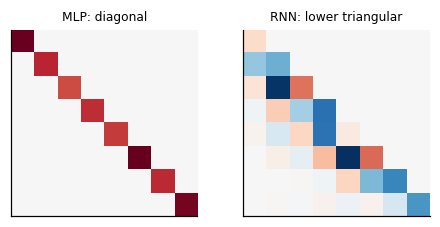

In [18]:
# Fig. 5: an MLP applied at each time step has a diagonal time Jacobian (iota = 0);
# an RNN's is lower triangular (iota > 0).
T = 8                              # number of time steps
torch.manual_seed(7)
mlp = nn.Sequential(nn.Linear(1, 6), nn.Tanh(), nn.Linear(6, 1))
xs = torch.randn(T, requires_grad=True)
J_mlp = jacobian(torch.stack([mlp(xs[t:t + 1]) for t in range(T)]), xs)

rnn_cell, readout = nn.RNNCell(1, 6), nn.Linear(6, 1)
h, ys = torch.zeros(1, 6), []
for t in range(T):
    h = rnn_cell(xs[t].reshape(1, 1), h)
    ys.append(readout(h))
J_rnn = jacobian(ys, xs)

measures(J_mlp, "MLP over time")
measures(J_rnn, "RNN over time")

fig, axs = plt.subplots(1, 2, figsize=(5, 2.2))
plot_heatmap(axs[0], J_mlp, "MLP: diagonal")
plot_heatmap(axs[1], J_rnn, "RNN: lower triangular")
plt.show()

### Quantifying duration: EMA channels on a logistic ladder (Eq. 3, Fig. 6)
$h^{(i)}_t=\delta_i h^{(i)}_{t-1}+(1-\delta_i)x_t$, $y_t=\sum_i h^{(i)}_t$, six decays $\delta_i=\sigma(\mu+s z_i)$ with $z=\mathrm{linspace}(-1,1,6)$, window $T=12$, incoming state fixed. The Jacobian is computed with autograd; in closed form it is $J_{ts}=\sum_i(1-\delta_i)\delta_i^{t-s}$ for $t\ge s$.

In [19]:
# Eq. 3, Fig. 6: six EMA channels with decays on a logistic ladder. Sweep the ladder's
# centre mu; record mean decay, transparency and integrity of the T x T time Jacobian.
T = 12                             # window length
Zl = np.linspace(-1, 1, 6)         # ladder positions z_i of the six channels
mus = np.linspace(-6, 6, 241)      # ladder centres mu
spreads = np.linspace(0, 6, 25)    # ladder spreads s, for panel (g)


def ema_jacobian(decays, T=T):
    """Autograd Jacobian (T x T numpy array) of y_t = sum_i h^(i)_t w.r.t. x_1..x_T, where
    h^(i)_t = delta_i h^(i)_{t-1} + (1 - delta_i) x_t from zero initial state."""
    decays = torch.as_tensor(decays)
    x = torch.zeros(T, requires_grad=True)
    h, out = torch.zeros(len(decays)), []
    for t in range(T):
        h = decays * h + (1 - decays) * x[t]
        out.append(h.sum())
    return jacobian(out, x).numpy()


def sweep(s):
    """For ladder spread s, return an array of rows (mean decay, rho, iota), one per mu."""
    rows = []
    for mu in mus:
        decays = expit(mu + s * Zl)
        J = ema_jacobian(decays)
        rows.append((decays.mean(), as_float(transparency(J)), as_float(integrity(J))))
    return np.array(rows)


def peak_integral_rank(R):
    """Largest rho * iota over the rows of a sweep."""
    return (R[:, 1] * R[:, 2]).max()


R_spread, R_single = sweep(3.0), sweep(0.0)     # spread s = 3; one decay (s = 0)
peaks = np.array([peak_integral_rank(sweep(s)) for s in spreads])
for label, R in (("spread s=3", R_spread), ("single decay", R_single)):
    i = np.argmax(R[:, 1] * R[:, 2])
    print(f"{label:13s}: peak integral rank {R[i, 1] * R[i, 2]:.2f} "
          f"at mean decay {R[i, 0]:.2f}")
print(f"largest peak over spreads s <= 6: {peaks.max():.2f}")

spread s=3   : peak integral rank 1.38 at mean decay 0.64
single decay : peak integral rank 0.85 at mean decay 0.82
largest peak over spreads s <= 6: 1.44


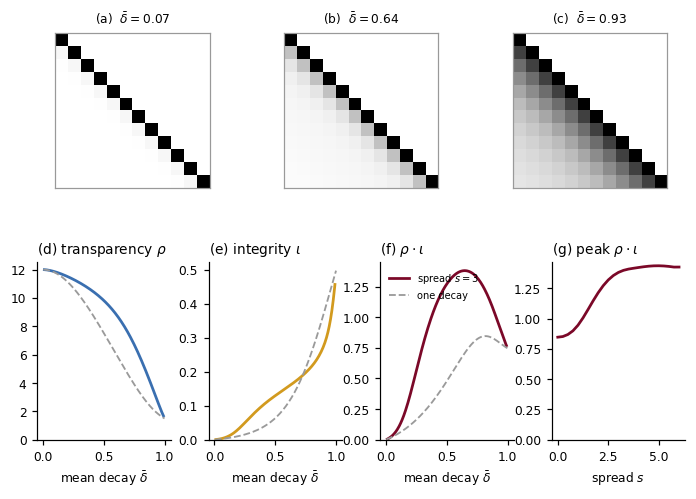

In [20]:
# Fig. 6 (ema_duration.pdf). Top row (a)-(c): |J| at three mean decays of the s = 3
# ladder. Bottom row: (d) rho, (e) iota, (f) rho*iota against mean decay; (g) peak vs spread.
fig = plt.figure(figsize=(7.6, 4.8))
gs = fig.add_gridspec(2, 12, height_ratios=[1, 1.15], hspace=0.45, wspace=2.0)

# Panels (a)-(c): Jacobian magnitude, normalised to mean 1, nearest each target mean decay.
for k, (target, panel) in enumerate([(0.07, "a"), (0.64, "b"), (0.93, "c")]):
    i = np.argmin(abs(R_spread[:, 0] - target))
    J = np.abs(ema_jacobian(expit(mus[i] + 3 * Zl)))
    J /= J.mean()
    ax = fig.add_subplot(gs[0, 4 * k:4 * k + 4])
    ax.imshow(J, cmap="Greys", vmin=0, vmax=np.percentile(J, 99))
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("0.6")
    ax.set_title(f"({panel})  $\\bar\\delta={R_spread[i, 0]:.2f}$", fontsize=8)

# Panels (d)-(f): each measure against mean decay, spread ladder vs one decay.
panels = [
    ("(d) transparency $\\rho$", R_spread[:, 1], R_single[:, 1], BLUE),
    ("(e) integrity $\\iota$", R_spread[:, 2], R_single[:, 2], GOLD),
    ("(f) $\\rho\\cdot\\iota$", R_spread[:, 1] * R_spread[:, 2],
     R_single[:, 1] * R_single[:, 2], BURG),
]
for k, (title, y_spread, y_single, color) in enumerate(panels):
    ax = fig.add_subplot(gs[1, 3 * k:3 * k + 3])
    ax.set_title(title, fontsize=9, loc="left")
    ax.plot(R_spread[:, 0], y_spread, color=color, lw=1.8, label="spread $s=3$")
    ax.plot(R_single[:, 0], y_single, color=GREY, lw=1.2, ls="--", label="one decay")
    ax.set_ylim(0, None)
    ax.set_xlabel("mean decay $\\bar\\delta$")
ax.legend(frameon=False, fontsize=6.5, loc="upper left")     # on panel (f) only

# Panel (g): peak integral rank against ladder spread.
ax = fig.add_subplot(gs[1, 9:12])
ax.set_title("(g) peak $\\rho\\cdot\\iota$", fontsize=9, loc="left")
ax.plot(spreads, peaks, color=BURG, lw=1.8)
ax.set_ylim(0, None)
ax.set_xlabel("spread $s$")

fig.savefig(f"{FIG_DIR}/ema_duration.pdf", bbox_inches="tight")
plt.show()

The dense-triangle limit is opaque because its rows are nested prefixes: row $t$ sums the first $t$ inputs, so one direction carries most of the mass.

In [21]:
# The dense lower triangle (slow-decay limit): rows are nested prefixes, so the top
# singular direction carries most of the mass.
Lt = np.tril(np.ones((T, T)))
sing_vals = np.linalg.svd(Lt, compute_uv=False)
top_share = sing_vals[0] ** 2 / (sing_vals ** 2).sum()
print(f"lower-triangular ones: rho={transparency(Lt):.2f}, iota={integrity(Lt):.2f}, "
      f"share of mass in top direction {top_share:.0%}")

lower-triangular ones: rho=1.49, iota=0.50, share of mass in top direction 81%


### EMAs select the experienced present (Def. 4, *duration*)
The sweep above compares dynamics over a fixed window, with the state entering it held fixed. To *select* the present, Def. 4 takes outputs $y_{t-T+1:t}$ with the input cut at the whole past that makes a difference, and asks which $T$ locally maximises $\iota_\rho(J_{y_{t-T+1:t}\leftarrow x_{\le t}})$ and beats the baseline of a single moment.

`J_cut` builds that Jacobian directly: $T$ output rows, and one column for every input far enough back that the slowest channel has decayed below $10^{-12}$ (`K_past` steps before the window). The ladder is the one of Fig. 6 with spread $s=3$, shifted so that the slowest timescale $-1/\log\delta_{\max}$ is exactly 50; its mean decay is 0.62.

1. **The cut belongs at the whole past.** By *extend*, the cut moves upstream while integral rank does not fall. Integral rank rises monotonically with cut depth $k$, so the cut does go to the whole past.
2. **The window.** Scan $T$ and list every local maximum.

In [22]:
# Def. 4, *duration*: Jacobians of a window of T outputs w.r.t. the whole relevant past.
def ema_kernel(decays, L):
    """Impulse response sum_i (1 - delta_i) delta_i^l of the summed EMA channels, l < L."""
    lags = np.arange(L)
    return sum((1 - delta) * delta ** lags for delta in np.atleast_1d(decays))


def J_cut(decays, T, K_past=None):
    """Outputs y_{t-T+1..t}; inputs x_{t-T-K_past+1..t} (the state before that is zero).

    By default K_past reaches back until the slowest channel has decayed below 1e-12.
    Returns the T x (T + K_past) Jacobian.
    """
    if K_past is None:
        K_past = int(np.ceil(np.log(1e-12) / np.log(np.max(decays))))
    L = T + K_past
    kern = ema_kernel(decays, L)
    lag = (K_past + np.arange(T))[:, None] - np.arange(L)[None, :]
    return np.where(lag >= 0, kern[np.clip(lag, 0, None)], 0.0)


def local_maxima(Ts, v):
    """List the (T, v rounded to 3 dp) pairs at which v is a local maximum, ends included."""
    return [(int(Ts[i]), round(float(v[i]), 3)) for i in range(len(v))
            if (i == 0 or v[i] >= v[i - 1]) and (i == len(v) - 1 or v[i] >= v[i + 1])]


# The Fig. 6 ladder (spread s = 3), shifted so its slowest timescale -1/log(delta_max) is 50.
ladder = expit(logit(np.exp(-1 / 50)) - 3 + 3 * Zl)
print(f"ladder: decays {ladder.round(3)}, mean {ladder.mean():.3f}, "
      f"slowest timescale {-1 / np.log(ladder.max()):.1f}")

# Point 1: integral rank rises with the cut depth k, so the cut goes to the whole past.
CUT_DEPTHS = (0, 4, 16, 64, 256, 1024)
depth_scan = [as_float(integral_rank(J_cut(ladder, 155, k))) for k in CUT_DEPTHS]
print("cut depth k = 0, 4, 16, 64, 256, 1024 at T=155:", np.round(depth_scan, 3))

ladder: decays [0.109 0.289 0.575 0.818 0.937 0.98 ], mean 0.618, slowest timescale 50.0
cut depth k = 0, 4, 16, 64, 256, 1024 at T=155: [5.938 5.996 6.222 6.695 6.952 6.958]


In [23]:
# Point 2: scan the window T and list the local maxima, for a single timescale tau and
# for the spread ladder.
Ts_single = np.arange(1, 41)       # windows scanned for one timescale
single_scans = {}                  # tau -> integral rank for each window in Ts_single
for tau in (2, 5, 10):
    scan = np.array([as_float(integral_rank(J_cut([np.exp(-1 / tau)], T))) for T in Ts_single])
    single_scans[tau] = scan
    i = 1 + np.argmax(scan[1:])    # best window with T > 1
    print(f"single timescale tau={tau:2d}: T=1 scores {scan[0]:.2f}; "
          f"best multi-step window T={Ts_single[i]} "
          f"(integral rank {scan[i]:.3f}); local maxima {local_maxima(Ts_single, scan)}")

Ts = np.arange(1, 321)             # windows scanned for the ladder
ladder_scan = np.array([as_float(integral_rank(J_cut(ladder, T))) for T in Ts])
i = ladder_scan.argmax()
print(f"spread: T=1 scores 1, T=2 {ladder_scan[1]:.2f}; "
      f"global max T={Ts[i]}, integral rank {ladder_scan[i]:.2f}; "
      f"local maxima {local_maxima(Ts, ladder_scan)}")

single timescale tau= 2: T=1 scores 1.00; best multi-step window T=4 (integral rank 0.787); local maxima [(1, 1.0), (4, 0.787)]
single timescale tau= 5: T=1 scores 1.00; best multi-step window T=9 (integral rank 0.887); local maxima [(1, 1.0), (9, 0.887)]
single timescale tau=10: T=1 scores 1.00; best multi-step window T=18 (integral rank 0.904); local maxima [(1, 1.0), (18, 0.904)]
spread: T=1 scores 1, T=2 0.84; global max T=155, integral rank 6.96; local maxima [(1, 1.0), (155, 6.958)]


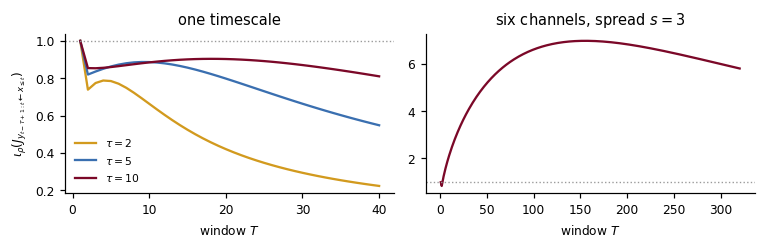

In [24]:
# Window scans; the dotted line is the single-moment baseline (integral rank 1).
fig, axs = plt.subplots(1, 2, figsize=(7.0, 2.3))

# Left: one timescale tau.
for tau, color in ((2, GOLD), (5, BLUE), (10, BURG)):
    axs[0].plot(Ts_single, single_scans[tau], color=color, label=f"$\\tau={tau}$")
axs[0].axhline(1, color=GREY, ls=":", lw=0.9)
axs[0].set(xlabel="window $T$",
           ylabel="$\\iota_\\rho(J_{y_{t-T+1:t}\\leftarrow x_{\\leq t}})$",
           title="one timescale")
axs[0].legend(frameon=False, fontsize=7)

# Right: six channels, spread s = 3.
axs[1].plot(Ts, ladder_scan, color=BURG)
axs[1].axhline(1, color=GREY, ls=":", lw=0.9)
axs[1].set(xlabel="window $T$", title="six channels, spread $s=3$")

fig.tight_layout()
plt.show()

The selected present scales with the slowest timescale. Shifting the ladder so that its slowest timescale is 25 or 100 steps (same spread $s=3$) selects about three times that timescale each time. The scan is coarse (geometric grid), then refined around the best window.

In [25]:
def selected_present(tau):
    """Window T selected for the s = 3 ladder whose slowest timescale is tau.

    Coarse geometric scan of T up to 8 tau, then every T between the neighbours of the
    best coarse window. Returns (T, its integral rank).
    """
    lad = expit(logit(np.exp(-1 / tau)) - 3 + 3 * Zl)

    def score(T):
        return as_float(integral_rank(J_cut(lad, T)))

    coarse = np.unique(np.geomspace(1, 8 * tau, 120).astype(int))
    i = int(np.argmax([score(T) for T in coarse]))
    fine = np.arange(coarse[max(i - 1, 0)], coarse[min(i + 1, len(coarse) - 1)] + 1)
    fine_scores = [score(T) for T in fine]
    return int(fine[np.argmax(fine_scores)]), max(fine_scores)


# The selected present scales with the slowest timescale.
for tau in (25, 50, 100):
    T_sel, best_rank = selected_present(tau)
    print(f"slowest timescale {tau:3d}: selected present {T_sel} steps "
          f"({T_sel / tau:.2f} x), integral rank {best_rank:.2f}")

slowest timescale  25: selected present 77 steps (3.08 x), integral rank 4.07
slowest timescale  50: selected present 155 steps (3.10 x), integral rank 6.96
slowest timescale 100: selected present 312 steps (3.12 x), integral rank 11.02


Every window scan has two local maxima: the single moment ($T=1$, integral rank exactly 1) and an extended window. The *duration* instance of Def. 4 asks for a local maximum that beats the baseline of a single moment, so one timescale (extended maxima 0.79–0.90, at $T=4,9,18$ for $\tau=2,5,10$) selects no extended present, while the spread of timescales selects 155 steps. How far back the Jacobian's cut reaches (here until the slowest channel has decayed below $10^{-12}$) makes no difference once it covers the slowest timescale.

## 6. Spatial structure: convolution (§3.4, App. "Closed form measures for convolutions")
On a periodic $N\times N$ grid, $\rho(J)$ is the participation ratio of the kernel's power spectrum and $\iota(J)=1-\max_{\omega\neq0}|\varphi(\omega)|$ with $\varphi$ the DFT of $|k|/\|k\|_1$.

In [26]:
# Closed-form integrity of a periodic Gaussian blur (sd = 2) vs its small-kernel approximation.
for N in (16, 32):
    dx = np.minimum(np.arange(N), N - np.arange(N))            # periodic distance to 0
    kernel = np.exp(-(dx[:, None] ** 2 + dx[None, :] ** 2) / 8)  # Gaussian, sd = 2, at 0
    approx = 1 - np.exp(-2 * np.pi ** 2 * 4 / N ** 2)
    print(f"Gaussian blur sd=2 on a {N}x{N} grid: integrity {conv_integrity(kernel, N):.4f}, "
          f"approximation 1-exp(-2 pi^2 sd^2/N^2) = {approx:.4f}")

Gaussian blur sd=2 on a 16x16 grid: integrity 0.2653, approximation 1-exp(-2 pi^2 sd^2/N^2) = 0.2654
Gaussian blur sd=2 on a 32x32 grid: integrity 0.0742, approximation 1-exp(-2 pi^2 sd^2/N^2) = 0.0742


## 7. Jacobian facets can resemble inputs (§3.5, Eq. 4)
For a bias-free relu net, $y_i=\langle J_{y_i\leftarrow x},x\rangle$: each facet's similarity to the input *is* that output. The identity fails for sigmoids.

In [27]:
# Eq. 4: for a bias-free relu net, <J_{y_i <- x}, x> = y_i exactly; not so for sigmoids.
torch.manual_seed(8)
for act in (nn.ReLU(), nn.Sigmoid()):
    net = nn.Sequential(nn.Linear(4, 6, bias=False), act, nn.Linear(6, 3, bias=False))
    x = torch.randn(4)
    J = input_jacobian(net, x)
    max_gap = (J @ x - net(x)).abs().max().item()
    print(f"{type(act).__name__:8s} max |<J_yi, x> - y_i| = {max_gap:.2e}")

ReLU     max |<J_yi, x> - y_i| = 5.55e-17
Sigmoid  max |<J_yi, x> - y_i| = 4.98e-01


## 8. Vivid and obscure errors (§3.6)
Stacking the logits $y$ and the cross-entropy loss $\ell$ as outputs gives the $(n+1)\times p$ Jacobian whose last row, the loss facet, is $e^\intercal J_{y\leftarrow W}$ with $e=\mathrm{softmax}(y)-\mathbf 1_c$. It fades as the net learns.

In [28]:
# §3.6: the loss facet (last row of the Jacobian of [logits; loss] w.r.t. the last layer's
# weights) equals e^T J_y with e = softmax(y) - onehot(c), and fades as the net learns.
torch.manual_seed(1)
net = nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 10))
x, c = Xd[0], yd[0]                # one training image and its class
opt = torch.optim.SGD(net.parameters(), 0.1)
for step in range(61):
    # Every 20 steps: the loss facet's size and the identity facet == e^T J_y.
    if step % 20 == 0:
        y = net(x)
        loss = nn.functional.cross_entropy(y[None], c[None])
        J = jacobian([y, loss], [net[2].weight])              # (n+1) x p, last layer
        e = torch.softmax(y, 0) - nn.functional.one_hot(c, 10)
        facet_share = J[-1].norm() / J.norm()
        print(f"step {step:2d}: loss {loss.item():.3f}  "
              f"|loss facet| {J[-1].norm().item():.3f} "
              f"({facet_share.item():.1%} of the Jacobian)  "
              f"facet == e^T J_y: {torch.allclose(J[-1], e @ J[:-1])}")
    # One SGD step on this example.
    opt.zero_grad()
    nn.functional.cross_entropy(net(x)[None], c[None]).backward()
    opt.step()

step  0: loss 2.163  |loss facet| 0.817 (28.3% of the Jacobian)  facet == e^T J_y: True
step 20: loss 0.018  |loss facet| 0.081 (0.6% of the Jacobian)  facet == e^T J_y: True
step 40: loss 0.007  |loss facet| 0.033 (0.2% of the Jacobian)  facet == e^T J_y: True
step 60: loss 0.004  |loss facet| 0.020 (0.1% of the Jacobian)  facet == e^T J_y: True


## 9. The structure of attention (§3.7, Eq. 5)
In $\mathrm{softmax}(XW_Q(XW_K)^\intercal)XW_{VO}$ the key–query (KQ) path passes gradients while attention is diffuse, and almost none once attention concentrates. The value–output (VO) path always passes them.

In [29]:
# §3.7, Eq. 5: one causal attention head. Gradients through the key-query (KQ) path vanish
# as attention concentrates (low temperature); the value-output (VO) path keeps passing them.
torch.manual_seed(9)
N_TOKENS, D_MODEL = 6, 4           # sequence length, model width
X = torch.randn(N_TOKENS, D_MODEL)
Wq, Wk, Wvo = (torch.randn(D_MODEL, D_MODEL) for _ in range(3))
causal_mask = torch.triu(torch.ones(N_TOKENS, N_TOKENS), 1).bool()


def attention(X, temp, path):
    """path='kq': only the attention pattern depends on X; 'vo': only the values do.

    Returns the attention matrix Pi and the head's output Pi X W_VO.
    """
    Xs, Xv = (X, X.detach()) if path == "kq" else (X.detach(), X)
    scores = (Xs @ Wq) @ (Xs @ Wk).T / temp
    Pi = torch.softmax(scores.masked_fill(causal_mask, -torch.inf), -1)
    return Pi, Pi @ Xv @ Wvo


for temp, label in ((8.0, "diffuse"), (0.05, "concentrated")):
    Xg = X.clone().requires_grad_(True)
    Pi, out_kq = attention(Xg, temp, "kq")
    _, out_vo = attention(Xg, temp, "vo")
    min_row_max = Pi.max(1).values.min().item()    # smallest per-row maximum attention
    print(f"{label:12s} max attention per row {min_row_max:.2f}   "
          f"||J_KQ|| = {jacobian(out_kq, Xg).norm().item():.2e}   "
          f"||J_VO|| = {jacobian(out_vo, Xg).norm().item():.2f}")

diffuse      max attention per row 0.35   ||J_KQ|| = 5.14e+00   ||J_VO|| = 7.49
concentrated max attention per row 1.00   ||J_KQ|| = 8.10e-08   ||J_VO|| = 10.71


## 10. Shattered structure at initialisation (§3.8, Fig. 9)
A relu MLP with 1-d input and output and hidden layers of 200 units; weights are He-scaled normals truncated to $[-2,2]$, and the first layer has a random bias. The 256 grid points in $[-2,2]$ are standardised and passed through the net as one batch. Before each relu every unit is centred by its mean over the grid; the means are held fixed when differentiating, as batch normalisation does at inference, so the gradient of the summed output is each input's own 1-d Jacobian. `depth = 24` builds `depth + 2` hidden layers: 24 followed by a relu, then two linear layers.

Panel (a) plots the gradients over the grid; panel (b) is $|(g_i-\bar g)(g_j-\bar g)|/\mathrm{var}(g)$.

In [30]:
# §3.8, Fig. 9, following Balduzzi et al. (2017): He-scaled truncated-normal weights,
# hidden layers centred over the input grid before each relu.
from scipy.stats import truncnorm

GRID_SIZE = 256                    # grid points in [-2, 2]


def shatter_weights(depth, width=200, seed=0):
    """A first-layer bias, then He-scaled matrices for depth + 2 hidden layers.

    All entries are standard normals truncated to [-2, 2]. Returns (bias, list of matrices).
    """
    rng = np.random.default_rng(seed)

    def truncated_normal(*shape):
        return torch.tensor(truncnorm.rvs(-2, 2, size=shape, random_state=rng))

    dims = [1] + [width] * (depth + 2) + [1]
    bias = truncated_normal(width)
    return bias, [np.sqrt(2 / dims[i]) * truncated_normal(dims[i + 1], dims[i])
                  for i in range(len(dims) - 1)]


def shatter_net(x, bias, Ws):
    """Forward pass: x is 1 x n, one column per grid point."""
    x = Ws[0] @ x + bias[:, None]
    for W in Ws[1:-2]:                                         # depth relu layers
        x = W @ torch.relu(x - x.mean(1, keepdim=True).detach())   # centred over the grid (means held
                                                                   # fixed), then relu
    for W in Ws[-2:]:                                          # final two layers: linear
        x = W @ x
    return x


# The input grid, standardised (1 x GRID_SIZE).
grid = torch.linspace(-2, 2, GRID_SIZE)
grid_centred = grid - grid.mean()
x_std = (grid_centred / torch.sqrt((grid_centred ** 2).mean() + 0.001)).reshape(1, -1)


def shatter_gradients(depth, seed=0):
    """Gradient of the summed output w.r.t. each standardised grid input, for the net of the
    given depth drawn with `seed`. Returns a numpy vector of length GRID_SIZE."""
    x = x_std.clone().requires_grad_(True)
    total_output = shatter_net(x, *shatter_weights(depth, seed=seed)).sum()
    return torch.autograd.grad(total_output, x)[0].ravel().numpy()


def gradient_covariance(g):
    """Fig. 9b matrix |(g_i - mean g)(g_j - mean g)| / var(g)."""
    y = g - g.mean()
    y = y / np.sqrt((y ** 2).mean())
    return np.abs(np.outer(y, y))

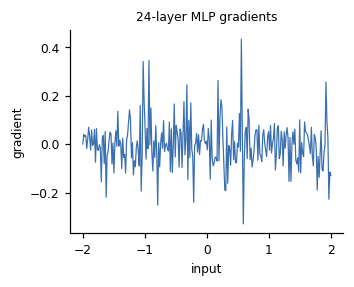

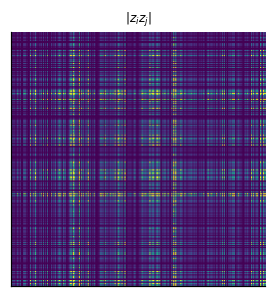

In [31]:
# Fig. 9a (24_layer.pdf): gradients over the grid for one 24-layer net.
grads_24 = shatter_gradients(24)
fig, ax = plt.subplots(figsize=(3.2, 2.4))
ax.plot(grid, grads_24, color=BLUE, lw=0.8)
ax.set(xlabel="input", ylabel="gradient")
ax.set_title("24-layer MLP gradients", fontsize=8)
fig.savefig(f"{FIG_DIR}/24_layer.pdf", bbox_inches="tight")
plt.show()

# Fig. 9b (24_layer_covar.pdf): the gradient covariance.
cov = gradient_covariance(grads_24)
fig, ax = plt.subplots(figsize=(3.0, 3.0))
ax.imshow(cov, cmap="viridis", vmin=0, vmax=np.percentile(cov, 99))
ax.set_title(r"$|z_iz_j|$", fontsize=8)
ax.set_xticks([])
ax.set_yticks([])
fig.savefig(f"{FIG_DIR}/24_layer_covar.pdf", bbox_inches="tight")
plt.show()

In [32]:
# One net gives one gradient per grid point; across 50 random nets, how correlated are the
# gradients at two grid points (neighbours, and 32 apart)?
N_NETS = 50
for depth in (2, 24):
    grads = np.stack([shatter_gradients(depth, seed=s) for s in range(N_NETS)])  # nets x grid
    C = np.corrcoef(grads.T)
    print(f"depth {depth:2d}: correlation of gradients across nets at neighbouring "
          f"grid points {np.mean(np.diag(C, 1)):.2f}, "
          f"at distance 32: {np.mean(np.diag(C, 32)):.2f}")

# On average half of the relu units are active at any given input (24-layer net, seed 0)
x_act = shatter_weights(24, seed=0)
h_act, fractions = x_act[1][0] @ x_std + x_act[0][:, None], []
for W in x_act[1][1:-2]:
    z = h_act - h_act.mean(1, keepdim=True)
    fractions.append((z > 0).double().mean(0))
    h_act = W @ torch.relu(z)
fractions = torch.stack(fractions)
print(f"fraction of relu units active per input: mean {fractions.mean():.2f}, "
      f"range {fractions.min():.2f}-{fractions.max():.2f}")

depth  2: correlation of gradients across nets at neighbouring grid points 0.99, at distance 32: 0.64
depth 24: correlation of gradients across nets at neighbouring grid points -0.01, at distance 32: 0.01
fraction of relu units active per input: mean 0.50, range 0.36-0.61


Across random nets, the gradients at neighbouring grid points are almost perfectly correlated at depth 2, and uncorrelated at the depth of Fig. 9: by then the spatial structure of the grid is gone from the gradients, as §3.8 describes.

## 11. Distinct and confused facets (§3.9, Def. 5)
A trunk mixes freely; its activations then split into two branches that never interact again. The coherency matrix $G=J_{y\leftarrow a_l}J_{y\leftarrow a_l}^\intercal$ is block diagonal, giving two distinct ideas. By Eq. 6 the parameter Jacobian of layer $l$ has the same left singular vectors, so its coherency matrix is block diagonal too.

In [33]:
# Def. 5: a trunk feeding two branches that never interact again has a block-diagonal
# coherency matrix (two distinct ideas), from the activation and the parameter Jacobian alike.
class SplitCircuit(nn.Module):
    """A 3 -> 8 relu trunk; units 0-3 feed branch a, units 4-7 branch b (2 outputs each)."""

    def __init__(self):
        super().__init__()
        self.trunk, self.a, self.b = nn.Linear(3, 8), nn.Linear(4, 2), nn.Linear(4, 2)

    def forward(self, x):
        z = torch.relu(self.trunk(x))
        return torch.cat([self.a(z[:4]), self.b(z[4:])])


torch.manual_seed(12)
circuit, x = SplitCircuit(), torch.randn(3)
J_a = input_jacobian(circuit, x, input_names=["trunk"])          # J_{y <- a_l}
J_W = parameter_jacobian(circuit, x, param_names=["trunk.weight"])
print("coherency of J_{y<-a_l}:\n", coherency(J_a).detach().numpy())
print("distinct ideas: from J_{y<-a_l}", distinct_ideas(J_a),
      "| from the trunk's parameter Jacobian", distinct_ideas(J_W))
print("integrity of J_{y<-a_l}:", as_float(integrity(J_a)))

coherency of J_{y<-a_l}:
 [[ 0.02  -0.041  0.     0.   ]
 [-0.041  0.084  0.     0.   ]
 [ 0.     0.     0.017  0.002]
 [ 0.     0.     0.002  0.245]]
distinct ideas: from J_{y<-a_l} 2 | from the trunk's parameter Jacobian 2
integrity of J_{y<-a_l}: 1.1102230246251565e-16


Distinctness and integrity answer different questions (App. "Distinct ideas are not disconnected"). A Hadamard matrix has maximal integrity and a diagonal coherency matrix; so does $B=DV^\intercal$ from the SVD of a random matrix, whose coherency matrix is $D^2$ although $B$ is dense.

In [34]:
# Maximal integrity with a diagonal coherency matrix: the Hadamard matrix, and B = D V^T
# from the SVD of a random 5 x 5 matrix (dense, but coherency B B^T = D^2).
print("Hadamard: iota =", integrity(H), " distinct ideas =", distinct_ideas(H))
U, sing_vals, Vt = np.linalg.svd(np.random.default_rng(20).standard_normal((5, 5)))
B = np.diag(sing_vals) @ Vt
print(f"B = D V^T: iota = {integrity(B):.3f}, distinct ideas = {distinct_ideas(B)}")

Hadamard: iota = 0.9999999999999999  distinct ideas = 8
B = D V^T: iota = 0.484, distinct ideas = 5


## 12. Learning: higher-order structure (§3.10)
An SGD step $w_t=w_{t-1}-\eta\sum_i\nabla_w f_w(x_i)$ is itself an interaction, with Jacobians $J_{w_t\leftarrow x}=-\eta\nabla^2_{wx}$ and $J_{w_t\leftarrow w}=-\eta\nabla^2_w$ ($w_{t-1}$ stop-gradiented). Both come from `jacobian(..., create_graph=True)`.

In [35]:
# §3.10: the Jacobians of one SGD update w.r.t. the batch inputs (-eta d2f/dw dx) and the
# weights (-eta Hessian), through a gradient computed with create_graph=True.
torch.manual_seed(3)
net = nn.Sequential(nn.Linear(3, 4), nn.Tanh(), nn.Linear(4, 1))
params = list(net.parameters())
eta = 0.1                          # learning rate
xb = torch.randn(5, 3, requires_grad=True)      # batch of 5 inputs
grad = jacobian(net(xb).sum(), params, create_graph=True)[0]      # g_t, one row
update = -eta * grad                                                # w_t - w_{t-1}
J_wx, J_ww = jacobian(update, xb), jacobian(update, params)
print("J_{w_t<-x}:", tuple(J_wx.shape),
      f" rho={as_float(transparency(J_wx)):.2f} iota={as_float(integrity(J_wx)):.3f}")
print("J_{w_t<-w}:", tuple(J_ww.shape),
      f" rho={as_float(transparency(J_ww)):.2f} iota={as_float(integrity(J_ww)):.3f}")
print("J_{w_t<-w} is -eta * Hessian, symmetric:", torch.allclose(J_ww, J_ww.T))

J_{w_t<-x}: (21, 15)  rho=3.20 iota=0.359
J_{w_t<-w}: (21, 21)  rho=7.80 iota=0.000
J_{w_t<-w} is -eta * Hessian, symmetric: True


$\iota(J_{w_t\leftarrow w})=0$ is not a bug: the output of a one-hidden-layer net is a sum over hidden units, so its Hessian with respect to the weights splits unit by unit.

**One or many?** A batched forward pass is block diagonal over the batch; the weight update aggregates the whole batch, so its Jacobian is interwoven.

In [36]:
# The batched forward pass is block diagonal over the batch; the update mixes the batch.
J_forward = jacobian(net(xb), xb)          # batch x (batch * 3)
print(f"forward pass over the batch: iota = {as_float(integrity(J_forward)):.3f}   |   "
      f"weight update: iota = {as_float(integrity(J_wx)):.3f}")

forward pass over the batch: iota = 0.000   |   weight update: iota = 0.359


## 13. Appendix: equivalent forms of effective rank; integrity versus spanning trees
The three alternative formulas for effective rank agree with the definition; entropic rank shares its zero set and maximiser but grades differently.

In [37]:
# The definition of effective rank and its three equivalent forms agree; entropic rank differs.
A = np.random.default_rng(1).standard_normal((6, 4))
A_torch = torch.tensor(A)
print("definition", round(transparency(A), 6),
      "| trace ratio", round(as_float(effective_rank_trace(A_torch)), 6),
      "| inverse collision", round(as_float(effective_rank_collision(A_torch)), 6),
      "| CV form", round(as_float(effective_rank_cv(A_torch)), 6))
print("entropic rank", round(entropic_rank(A), 3),
      "(same zero set and maximiser, different grading)")

definition 2.917417 | trace ratio 2.917417 | inverse collision 2.917417 | CV form 2.917417
entropic rank 3.672 (same zero set and maximiser, different grading)


**Why integrity rather than a spanning-tree count.** The spanning-tree measure averages over the whole Laplacian spectrum, so one weak seam is a single small eigenvalue among many and barely registers. Two dense $8\times8$ blocks joined by a seam of weight $\epsilon$:

In [38]:
# Two dense 8 x 8 blocks joined by a seam of weight eps: integrity sees the seam,
# the spanning-tree cohesion barely does.
blocks = np.kron(np.eye(2), np.abs(np.random.default_rng(2).standard_normal((8, 8))) + 0.2)
seam_mask = 1 - np.kron(np.eye(2), np.ones((8, 8)))      # 1 on the off-diagonal blocks
print(" eps     integrity   spanning-tree cohesion")
for eps in (0, 1e-4, 1e-2, 0.1, 1):
    A = blocks + eps * seam_mask
    print(f"{eps:6g}   {integrity(A):9.4f}   {spanning_tree_cohesion(A):9.4f}")

 eps     integrity   spanning-tree cohesion
     0      0.0000      0.0000
0.0001      0.0002      0.7438
  0.01      0.0203      0.8632
   0.1      0.1838      0.9309
     1      0.8320      0.9886
